In [53]:
import gudhi
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import numpy as np
import matplotlib
from math import cos, sin, pi, atan

import sys 
sys.path.append('../Code/')
import modules as mod

In [202]:
    
def closure_lub(Points): 
        """ Find the closure under least upper boud of the critical points"""
        ## Todo: check that it works properly on an example
        ## Not the most efficient way to code this function 
    
        l = len(Points)
        for i in range(l): 
            p = Points[i]
            for j in range(i+1, l): 
                q = Points[j]
                if not mod.are_comparable(p,q):
                    lub = (max(p[0],q[0]), max(p[1],q[1]))
                    Points.append(lub)

        return list(set(Points))  
    
    
def plot_weighted_bottleneck(M,N,b =5, filename = 'weightedBottlneckDistance'): 
    
    Crit_M = M.closure_lub() 
    Crit_N = N.closure_lub() 
    C = list(set(Crit_M+Crit_N))
    Crit_MN = closure_lub(C)
    #print(len(Crit_MN))
    #Crit_MN=list(set(Crit_M+Crit_N))
    Lines = []
    DD = []
    k = 0
    Crit = []
    for i in range(len(Crit_MN)-1):
        p = Crit_MN[i]
        for j in range(i+1,len(Crit_MN)):
            q = Crit_MN[j] 
            line = mod.line_through_2points(Crit_MN[i], Crit_MN[j])
            if line.positive: 
                d = mod.compute_weighted_bottleneck(M,N,line)
                Lines.append(line)
                Crit.append([Crit_MN[i], Crit_MN[j]])
                DD.append(d)
    print('There are {} lines through critical points'.format(len(Lines)))
    #print('Bottleneck distance for lines through critical points: ')
    #print(D)
    if len(DD) > 0:
        print('Maximum distance for lines: {}'.format(max(DD)))
    else: 
        print('no positive line through pairs of ciritcal points')
   
    ## computing bottlneck for "every" line
    
    Theta = np.linspace(0,pi/2,100)[1:-1]
    B = np.linspace(-b,b,100)
    D= np.zeros((len(Theta), len(B)))
    T = []
    BB= []
    Dist = []
    for t in range(len(Theta)): 
        for n in range(len(B)): 
            s = sin(Theta[t])
            c = cos(Theta[t])
            maxm = max(s,c)
            line = mod.Line((c/maxm, s/maxm), (B[n],-B[n]))
            d = mod.compute_weighted_bottleneck(M,N,line)
            D[t,n] = d
            T.append(Theta[t])
            BB.append(B[n])
            Dist.append(d)
    val = max(Dist)
    idx = Dist.index(val)
    
    
    print('Maximum distance computed {}'.format(max(Dist)))
    #print(max(Dist))     
    plt.figure(figsize=(8,8))
    plt.scatter(T, BB, c= Dist,s = 10, cmap = "summer")
    plt.scatter(T[idx], BB[idx], marker = 'x', color = 'red')
    print('Value of theta for L_max: {}'.format(T[idx]))
    print('Value of b for L_max: {}'.format(BB[idx]))

    
    ## plot markers for the lines through critical points
    b_crit = []
    theta_crit = []
    for j in range(len(Lines)):
        Line = Lines[j]
        b= Line.b[0]
        theta = atan(Line.m[1]/Line.m[0])
        b_crit.append(b)
        theta_crit.append(theta)
    
    for j in range(len(Lines)): 
        plt.scatter(theta_crit[j], b_crit[j], marker = 'x', color = 'grey')
        #plt.text(theta_crit[j], b_crit[j], str(Crit[j]))
    if len(DD) > 0:
        val = max(DD)
        idx=DD.index(val)
        plt.scatter(theta_crit[idx], b_crit[idx], marker = 'x', color = 'black')
    ## plot titles
    plt.xlabel('theta')
    plt.ylabel('b')
    plt.title("Weighted bottleneck distance as a function of theta and b")
    plt.colorbar(label="Weighted distance", orientation="horizontal")
    plt.clim(0,max(Dist))
    plt.savefig(filename)
    plt.show()
    
def compute_weighted_bottleneck_distances(M,N,b=5): 
    
    Crit_M = M.closure_lub() 
    Crit_N = N.closure_lub() 
    C = list(set(Crit_M+Crit_N))
    Crit_MN = closure_lub(C)
    #print(len(Crit_MN))
    #Crit_MN=list(set(Crit_M+Crit_N))
    Lines = []
    DD = []
    k = 0
    Crit = []
    for i in range(len(Crit_MN)-1):
        p = Crit_MN[i]
        for j in range(i+1,len(Crit_MN)):
            q = Crit_MN[j] 
            line = mod.line_through_2points(Crit_MN[i], Crit_MN[j])
            if line.positive: 
                d = mod.compute_weighted_bottleneck(M,N,line)
                Lines.append(line)
                Crit.append([Crit_MN[i], Crit_MN[j]])
                DD.append(d)
    print('There are {} lines through critical points'.format(len(Lines)))
    #print('Bottleneck distance for lines through critical points: ')
    #print(D)
    if len(DD) > 0:
        print('Maximum distance for lines: {}'.format(max(DD)))
    else: 
        print('no positive line through pairs of ciritcal points')
    
    ## computing bottlneck for "every" line
    
    Theta = np.linspace(0,pi/2,100)[1:-1]
    B = np.linspace(-b,b,100)
    D= np.zeros((len(Theta), len(B)))
    T = []
    BB= []
    Dist = []
    for t in range(len(Theta)): 
        for n in range(len(B)): 
            s = sin(Theta[t])
            c = cos(Theta[t])
            maxm = max(s,c)
            line = mod.Line((c/maxm, s/maxm), (B[n],-B[n]))
            d = mod.compute_weighted_bottleneck(M,N,line)
            D[t,n] = d
            T.append(Theta[t])
            BB.append(B[n])
            Dist.append(d)
    val = max(Dist)
    idx = Dist.index(val)
    print('Maximum distance computed {}'.format(max(Dist)))
    print('Value of theta for L_max: {}'.format(T[idx]))
    print('Value of b for L_max: {}'.format(BB[idx]))


    
    s = sin(T[idx])
    c = cos(T[idx])
    maxm = max(s,c)
    L_max = mod.Line((c/maxm, s/maxm), (BB[idx],-BB[idx]))
    return T,BB, idx, L_max

## Example 1

2 quadrants inside each other 

In [215]:
x = 1
y = 3
rect_m1 = mod.Rectangle((0,np.inf),(np.inf,np.inf),(0,0),(np.inf, 0),1)
rect_m2 = mod.Rectangle((0,np.inf),(np.inf,np.inf),(x,y),(np.inf, 0),1)
M1 = mod.RectangleModule([rect_m1])
M2 = mod.RectangleModule([rect_m2])

In [216]:
## distance through line through critical points 
L1 = mod.line_through_2points((0,0),(x,y))
d1 = mod.compute_weighted_bottleneck(M1,M2, L1)
print(d1)

1.0


In [205]:
## distance through line of slope (1,1) and a critical point 
L2 = mod.Line((1,1),(0,0))
d2= mod.compute_weighted_bottleneck(M1,M2,L2)
print(d2)
L3 = mod.Line((1,1),(x,y))
d3= mod.compute_weighted_bottleneck(M1,M2,L3)
print(d3)


4.0
2.0


There are 1 lines through critical points
Maximum distance for lines: 2.0
Maximum distance computed 4.000000000000001
Value of theta for L_max: 0.04759988869075445
Value of b for L_max: 4.09090909090909


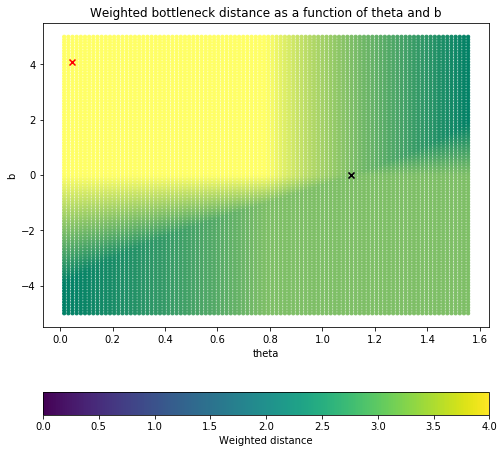

In [206]:
## distance parametrized by theta, b 
b = 5
plot_weighted_bottleneck(M1,M2,b)

In [207]:
T,B,idx,L_max = compute_weighted_bottleneck_distances(M1,M2,b)

There are 1 lines through critical points
Maximum distance for lines: 2.0
Maximum distance computed 4.000000000000001
Value of theta for L_max: 0.04759988869075445
Value of b for L_max: 4.09090909090909


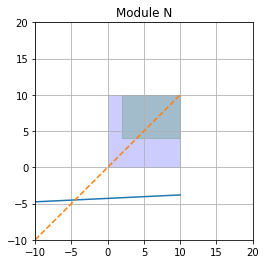

In [208]:
fig = plt.figure()
ax = fig.add_subplot(111)
ax.set_aspect(1)
plt.grid(visible = True )
## rectangles 
a1 = rect_m1.bottom_left
h1= 10- a1[0]
v1= 10- a1[1]
a2 = rect_m2.bottom_left 
h2= 10- a2[0]
v2= 10- a2[1]
rect1 = matplotlib.patches.Rectangle(a1,h1,v1,color ='blue', alpha = 0.2)
rect2 = matplotlib.patches.Rectangle(a2,h2,v2, color ='green',alpha = 0.2)

## lines
x = np.linspace(-10, 10, 1000)

b1 = L_max.b[0]
b2 = L_max.b[1]
m1 = L_max.m[0]
m2 = L_max.m[1]
plt.plot(x, m2*(x-b1)/m1 +b2, linestyle='solid') 
plt.plot(x,x,linestyle='dashed')

ax.add_patch(rect1)
ax.add_patch(rect2)
plt.xlim([-10, 20])
plt.ylim([-10, 20])

plt.title('Module N')  
#plt.savefig('moduleN')
plt.show()



### Example 2
quandrants not included in each other

In [209]:
x = 0
y = 2
a = 3
b =0
rect_n1 = mod.Rectangle((0,np.inf),(np.inf,np.inf),(a,b),(np.inf, 0),1)
rect_n2 = mod.Rectangle((0,np.inf),(np.inf,np.inf),(x,y),(np.inf, 0),1)
N1 = mod.RectangleModule([rect_n1])
N2 = mod.RectangleModule([rect_n2])

In [210]:
## distance through line of slope (1,1) and a critical point
L1 = mod.Line((1,1),(a,y))
d1= mod.compute_weighted_bottleneck(N1,N2,L1)
print(d1)
L2 = mod.Line((1,1),(a,b))
d2= mod.compute_weighted_bottleneck(N1,N2,L2)
print(d2)
L3 = mod.Line((1,1),(x,y))
d3= mod.compute_weighted_bottleneck(N1,N2,L3)
print(d3)



0.0
2.0
3.0


In [211]:
L_test = mod.Line((1,0.003),(-10,10))
d_test= mod.compute_weighted_bottleneck(N1,N2,L_test)
print(d_test)

0.009000000000000001


There are 0 lines through critical points
no positive line through pairs of ciritcal points
Maximum distance computed 3.000000000000002
Value of theta for L_max: 1.0471975511965979
Value of b for L_max: -6.2727272727272725


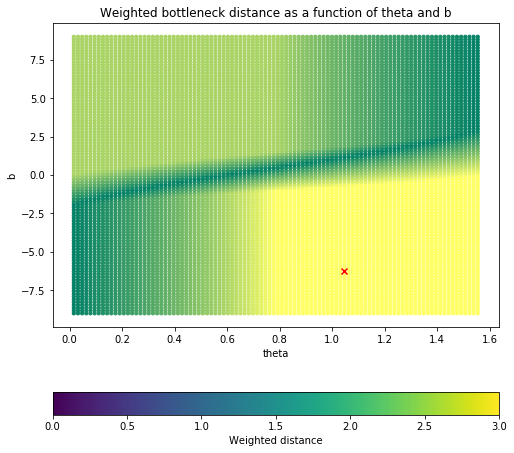

In [212]:
## distance parametrized by theta, b 
b = 9
plot_weighted_bottleneck(N1,N2,b)

In [213]:
T,B,idx,L_max = compute_weighted_bottleneck_distances(N1,N2,b)

There are 0 lines through critical points
no positive line through pairs of ciritcal points
Maximum distance computed 3.000000000000002
Value of theta for L_max: 1.0471975511965979
Value of b for L_max: -6.2727272727272725


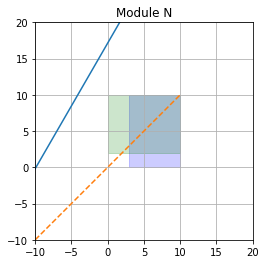

In [214]:
fig = plt.figure()
ax = fig.add_subplot(111)
ax.set_aspect(1)
plt.grid(visible = True )
## rectangles 
a1 = rect_n1.bottom_left
h1= 10- a1[0]
v1= 10- a1[1]
a2 = rect_n2.bottom_left 
h2= 10- a2[0]
v2= 10- a2[1]
rect1 = matplotlib.patches.Rectangle(a1,h1,v1,color ='blue', alpha = 0.2)
rect2 = matplotlib.patches.Rectangle(a2,h2,v2, color ='green',alpha = 0.2)

## lines
x = np.linspace(-10, 10, 1000)

b1 = L_max.b[0]
b2 = L_max.b[1]
m1 = L_max.m[0]
m2 = L_max.m[1]
plt.plot(x, m2*(x-b1)/m1 +b2, linestyle='solid') 
plt.plot(x,x,linestyle='dashed')

ax.add_patch(rect1)
ax.add_patch(rect2)
plt.xlim([-10, 20])
plt.ylim([-10, 20])

plt.title('Module N')  
#plt.savefig('moduleN')
plt.show()

